In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna()

X = df.drop("target", axis=1).values
y = df["target"].values

print("Dataset Shape:", df.shape)

Dataset Shape: (302, 14)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_base, X_val, y_train_base, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Base Training Shape:", X_train_base.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

Base Training Shape: (180, 13)
Validation Shape: (61, 13)
Testing Shape: (61, 13)


In [4]:
scaler = StandardScaler()

X_train_base_scaled = scaler.fit_transform(X_train_base)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [5]:
base_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42)
}

In [6]:
trained_base_models = {}

for name, model in base_models.items():

    model.fit(X_train_base_scaled, y_train_base)

    trained_base_models[name] = model

    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully
SVM trained successfully


C:\Users\mahir\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [7]:
meta_train = np.column_stack([
    model.predict_proba(X_train_base_scaled)[:, 1]
    for model in trained_base_models.values()
])

meta_val = np.column_stack([
    model.predict_proba(X_val_scaled)[:, 1]
    for model in trained_base_models.values()
])

meta_test = np.column_stack([
    model.predict_proba(X_test_scaled)[:, 1]
    for model in trained_base_models.values()
])

print("Meta Training Shape:", meta_train.shape)
print("Meta Validation Shape:", meta_val.shape)
print("Meta Testing Shape:", meta_test.shape)

Meta Training Shape: (180, 4)
Meta Validation Shape: (61, 4)
Meta Testing Shape: (61, 4)


In [8]:
meta_model = LogisticRegression(max_iter=1000)

meta_model.fit(meta_train, y_train_base)

print("Meta-model trained successfully")

Meta-model trained successfully


In [9]:
depth_values = [2, 3, 5, 7, 10]
best_depth = None
best_score = 0

for depth in depth_values:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_base_scaled, y_train_base)

    predictions = model.predict(X_val_scaled)

    score = np.mean(predictions == y_val)

    print("Depth:", depth, "Validation Accuracy:", round(score, 4))

    if score > best_score:
        best_score = score
        best_depth = depth

print("Best Decision Tree Depth:", best_depth)

Depth: 2 Validation Accuracy: 0.6721
Depth: 3 Validation Accuracy: 0.7049
Depth: 5 Validation Accuracy: 0.7049
Depth: 7 Validation Accuracy: 0.6885
Depth: 10 Validation Accuracy: 0.6885
Best Decision Tree Depth: 3


In [10]:
optimized_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=best_depth,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    )
}

optimized_trained_models = {}

for name, model in optimized_models.items():

    model.fit(X_train_base_scaled, y_train_base)

    optimized_trained_models[name] = model

optimized_meta_train = np.column_stack([
    model.predict_proba(X_train_base_scaled)[:, 1]
    for model in optimized_trained_models.values()
])

optimized_meta_val = np.column_stack([
    model.predict_proba(X_val_scaled)[:, 1]
    for model in optimized_trained_models.values()
])

optimized_meta_test = np.column_stack([
    model.predict_proba(X_test_scaled)[:, 1]
    for model in optimized_trained_models.values()
])

optimized_meta_model = LogisticRegression(max_iter=1000)

optimized_meta_model.fit(optimized_meta_train, y_train_base)

print("Optimized stacking model trained successfully")

Optimized stacking model trained successfully


C:\Users\mahir\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [11]:
def calculate_accuracy(actual, predicted):
    correct = np.sum(actual == predicted)
    return correct / len(actual)

comparison = []

for name, model in optimized_trained_models.items():

    predictions = model.predict(X_test_scaled)

    comparison.append({
        "Model": name,
        "Test Accuracy": calculate_accuracy(y_test, predictions)
    })

stacking_predictions = optimized_meta_model.predict(optimized_meta_test)

comparison.append({
    "Model": "Stacking Classifier",
    "Test Accuracy": calculate_accuracy(y_test, stacking_predictions)
})

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Model,Test Accuracy
0,Logistic Regression,0.8033
1,Decision Tree,0.8033
2,Random Forest,0.7541
3,SVM,0.7377
4,Stacking Classifier,0.8197


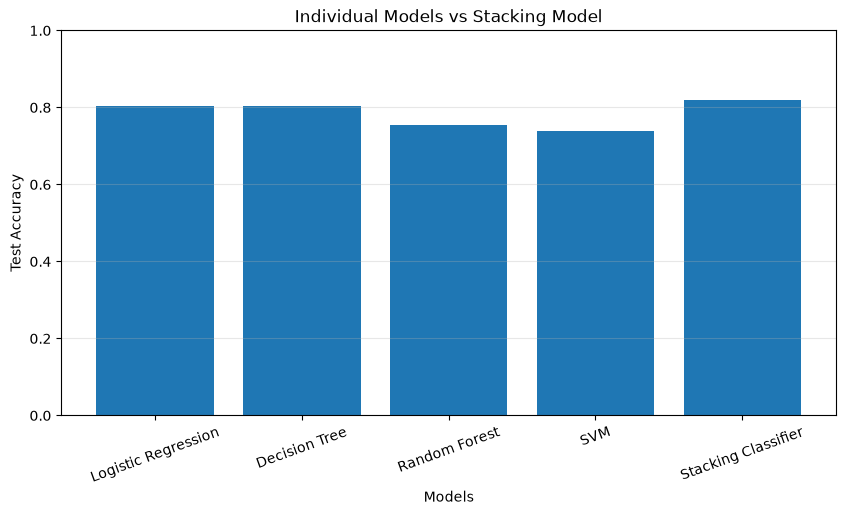

In [12]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy"]
)

plt.xlabel("Models")
plt.ylabel("Test Accuracy")
plt.title("Individual Models vs Stacking Model")

plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [13]:
print("""
Data Leakage Analysis:

1. The test dataset was kept separate from model training.
2. The scaler was fitted only on the base training data.
3. Validation data was used for hyperparameter selection.
4. The meta-model was trained using base-model predictions.

Important Limitation:
The meta-training features above are generated using predictions
on the same data used to train the base learners. This can cause
overfitting in the meta-model.

A production-grade stacking implementation should generate
out-of-fold predictions using cross-validation.
""")


Data Leakage Analysis:

1. The test dataset was kept separate from model training.
2. The scaler was fitted only on the base training data.
3. Validation data was used for hyperparameter selection.
4. The meta-model was trained using base-model predictions.

Important Limitation:
The meta-training features above are generated using predictions
on the same data used to train the base learners. This can cause
overfitting in the meta-model.

A production-grade stacking implementation should generate
out-of-fold predictions using cross-validation.



In [14]:
best_model = comparison_df.loc[
    comparison_df["Test Accuracy"].idxmax(), "Model"
]

print("Best Performing Model:", best_model)

print("""
Conclusion:

Model stacking combines predictions from multiple base classifiers
using a meta-model.

It can improve predictive performance by combining different
learning approaches.

The meta-model learns how to use predictions from base learners.

Proper validation and out-of-fold predictions are important
to prevent data leakage and overfitting.
""")


Best Performing Model: Stacking Classifier

Conclusion:

Model stacking combines predictions from multiple base classifiers
using a meta-model.

It can improve predictive performance by combining different
learning approaches.

The meta-model learns how to use predictions from base learners.

Proper validation and out-of-fold predictions are important
to prevent data leakage and overfitting.

